# M3 · Severity of the person: training notebook

**Goal:** from what the blackbox measures in a crash (+ the user's profile), predict the chance that the person is **seriously injured** (MAIS 3+), then turn that chance into our 4 dispatch levels: **low · medium · high · extreme**.

**Steps**
1. Load the training table built by `build_m3_dataset.py` (NASS-CDS 2010–15 + CISS 2017–23)
2. Choose the inputs (only things the blackbox or the app can know)
3. Keep usable rows
4. Split into train / test, by crash
5. Train 4 models: a simple rule, a classic formula, our AI model, and our AI model + seatbelt
6. Compare them
7. Look at what the model learned
8. Turn the probability into 4 levels
9. Save the model
10. Try it on example crashes

**Kernel:** pick **Python (solvex-m3)** at the top right. Everything runs on a normal PC in under a minute, no GPU needed.

## 1 · Load the data

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
SEED = 42

df = pd.read_csv("data/m3_training.csv")
groups = json.loads(Path("data/m3_training.columns.json").read_text())

print(f"Loaded {len(df):,} crash occupants, {df.shape[1]} columns")
print(f"  from NASS-CDS: {(df.source == 'nass').sum():,}   from CISS: {(df.source == 'ciss').sum():,}")
print("\nColumn groups:")
for name, cols in groups.items():
    print(f"  {name:<20} {', '.join(cols)}")

Loaded 59,844 crash occupants, 29 columns
  from NASS-CDS: 24,464   from CISS: 35,380

Column groups:
  id                   source, year, key, casewgt
  label                mais, iss, died, mais3plus, severity4
  blackbox_sensed      dv_kmh, pdof_car, direction_car, rollover, multi_impact, n_events
  needs_seat_position  seat_side, seat_row, pdof_seat, direction_seat
  from_app_profile     age, male, height_cm, weight_kg, bmi, body_group
  car_sensor_only      belt_used, airbag_deployed
  info_only            vehicle_age, complete_core


## 2 · Choose the inputs

Rule: the model may only use what we can know at crash time **without the car's own sensors**.

- **Blackbox:** ΔV (speed change), direction of the impact, rollover, multiple impacts
- **App profile:** age, sex, vehicle type

**Why no BMI:** in these databases a missing height/weight is not random, and it points in opposite directions: in CISS the people without BMI are mostly *uninjured* (never went to hospital), in NASS-CDS they are often the *dead* (never measured). At the same ΔV, missing BMI means 0.4× the risk in CISS and 1.8× in NASS. A model with BMI learns these "missing = answer" patterns, which don't exist in our app, so we leave BMI out.

The direction is an angle (0–360°). 359° and 1° are both "front", but as plain numbers they look far apart, so we give the model **sin** and **cos** of the angle instead.

The seatbelt is a car sensor, so the main model doesn't use it. We train a second model *with* it only to measure what we lose.

In [2]:
df["pdof_sin"] = np.sin(np.radians(df["pdof_car"]))
df["pdof_cos"] = np.cos(np.radians(df["pdof_car"]))
for g in ["utility", "van", "pickup"]:           # "car" is the reference type
    df[f"body_{g}"] = (df["body_group"] == g).astype(float)

FEATURES = {
    "dv_kmh":       "blackbox  speed change during impact (km/h)",
    "pdof_sin":     "blackbox  impact direction, sin part",
    "pdof_cos":     "blackbox  impact direction, cos part",
    "rollover":     "blackbox  car rolled over (1/0)",
    "multi_impact": "blackbox  more than one impact (1/0)",
    "age":          "profile   age (years)",
    "male":         "profile   sex (1 male, 0 female)",
    "body_utility": "profile   vehicle is an SUV (1/0)",
    "body_van":     "profile   vehicle is a van (1/0)",
    "body_pickup":  "profile   vehicle is a pickup (1/0)",
}
X_COLS = list(FEATURES)
X_COLS_BELT = X_COLS + ["belt_used"]
TARGET = "mais3plus"

print("Model inputs:")
for col, desc in FEATURES.items():
    print(f"  {col:<13} {desc}")
print(f"\nTarget: {TARGET} = 1 if the person has a serious injury (MAIS 3 or more)")

Model inputs:
  dv_kmh        blackbox  speed change during impact (km/h)
  pdof_sin      blackbox  impact direction, sin part
  pdof_cos      blackbox  impact direction, cos part
  rollover      blackbox  car rolled over (1/0)
  multi_impact  blackbox  more than one impact (1/0)
  age           profile   age (years)
  male          profile   sex (1 male, 0 female)
  body_utility  profile   vehicle is an SUV (1/0)
  body_van      profile   vehicle is a van (1/0)
  body_pickup   profile   vehicle is a pickup (1/0)

Target: mais3plus = 1 if the person has a serious injury (MAIS 3 or more)


## 3 · Keep usable rows

The blackbox always measures ΔV and the impact direction, and the profile always has age and sex, so we keep only rows where the database has those four.

**Why direction must be known:** in NASS-CDS, people whose impact direction is missing are injured 0.7× as often at the same ΔV (the reconstruction is skipped for some crash types). Keeping them would teach the model "no direction = safer", which never happens with our blackbox.

In [3]:
data = df[df["dv_kmh"].notna() & df["pdof_car"].notna() & df["age"].notna() & df["male"].notna()].copy()
data["case"] = data["key"].str.rsplit("_", n=2).str[0]   # crash id = key without vehicle and occupant

print(f"Rows before: {len(df):,}")
print(f"Rows kept:   {len(data):,}  (others have no delta-V, direction, age or sex)")
print(f"Crashes:     {data['case'].nunique():,}")
print(f"\nSeriously injured: {int(data[TARGET].sum()):,} people = {data[TARGET].mean():.1%} of rows")
print(f"In the real US population (using survey weights) it is only "
      f"{np.average(data[TARGET], weights=data['casewgt']):.1%}: investigators pick serious crashes more often.")
print("\nShare missing among kept rows:")
print((data[X_COLS_BELT].isna().mean() * 100).round(1).astype(str).add(" %").to_string())

Rows before: 59,844
Rows kept:   29,945  (others have no delta-V, direction, age or sex)
Crashes:     15,826

Seriously injured: 2,613 people = 8.7% of rows
In the real US population (using survey weights) it is only 2.2%: investigators pick serious crashes more often.

Share missing among kept rows:
dv_kmh          0.0 %
pdof_sin        0.0 %
pdof_cos        0.0 %
rollover        0.0 %
multi_impact    0.0 %
age             0.0 %
male            0.0 %
body_utility    0.0 %
body_van        0.0 %
body_pickup     0.0 %
belt_used       5.5 %


## 4 · Split into train and test, by crash

- **train (64 %)**: the model learns from it
- **validation (16 %)**: used while training to know when to stop, and to choose the level thresholds
- **test (20 %)**: never seen until the end; gives the honest score

We split **by crash**, not by person: two people in the same car share the same ΔV, so if one were in train and the other in test, the test would be too easy.

In [4]:
def split_by_crash(frame, test_size, seed):
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
                .split(frame, groups=frame["case"]))
    return frame.iloc[a], frame.iloc[b]

train_full, test = split_by_crash(data, 0.20, SEED)
train, valid = split_by_crash(train_full, 0.20, SEED)

for name, part in [("train", train), ("validation", valid), ("test", test)]:
    print(f"{name:<11} {len(part):>6,} people  {part['case'].nunique():>6,} crashes  "
          f"serious: {part[TARGET].mean():.1%}")
assert not set(train["case"]) & set(test["case"]), "a crash is in both train and test"
print("\nNo crash appears in both train and test ✓")

train       19,147 people  10,128 crashes  serious: 8.7%
validation   4,839 people   2,532 crashes  serious: 8.8%
test         5,959 people   3,166 crashes  serious: 8.7%

No crash appears in both train and test ✓


## 5 · Train the models

| Model | What it is | Why |
|---|---|---|
| **A · ΔV rule** | logistic regression on ΔV only | the simplest possible baseline |
| **B · Classic formula** | logistic regression on all inputs | how OnStar / URGENCY do it: one weight per input |
| **C · Our AI model** | LightGBM (gradient-boosted decision trees) | learns curves (risk jumps after ~30 km/h, rises with age) and handles missing values |
| **D · AI + seatbelt** | same as C + belt, trained on people whose belt use is known | only to measure what the belt is worth |

LightGBM builds hundreds of small decision trees, each one fixing the errors of the previous ones. We stop adding trees when the validation score stops improving. Belt use is unknown for ~7 % of people, and in NASS-CDS those are injured 2.75× as often (often ejected or killed), so D only learns from people whose belt use is known.

We also force **risk to never go down when ΔV goes up** (a "monotone constraint"), so the model can't learn something physically absurd.

In [5]:
y_train, y_valid, y_test = train[TARGET], valid[TARGET], test[TARGET]

print("A · ΔV rule ...")
model_a = make_pipeline(StandardScaler(), LogisticRegression())
model_a.fit(train[["dv_kmh"]], y_train)
print(f"   done: risk = sigmoid({model_a[-1].intercept_[0]:.2f} + {model_a[-1].coef_[0][0]:.2f} x scaled ΔV)")

print("B · Classic formula ...")
model_b = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
model_b.fit(train[X_COLS], y_train)
print("   done: one weight per input (positive = more risk)")
for col, w in sorted(zip(X_COLS, model_b[-1].coef_[0]), key=lambda t: -abs(t[1])):
    print(f"     {col:<13} {w:+.2f}")

LGB_PARAMS = dict(
    n_estimators=2000, learning_rate=0.03, num_leaves=15, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=SEED, verbose=-1,
)

def train_lgbm(cols, label, tr=None, va=None):
    tr = train if tr is None else tr
    va = valid if va is None else va
    print(f"{label} ...")
    model = lgb.LGBMClassifier(
        **LGB_PARAMS,
        monotone_constraints=[1 if c == "dv_kmh" else 0 for c in cols],
    )
    model.fit(
        tr[cols], tr[TARGET],
        eval_set=[(va[cols], va[TARGET])], eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(100)],
    )
    print(f"   done: stopped at {model.best_iteration_} trees "
          f"(validation AUC {model.best_score_['valid_0']['auc']:.3f})\n")
    return model

model_c = train_lgbm(X_COLS, "C · Our AI model")
model_d = train_lgbm(X_COLS_BELT, "D · AI + seatbelt",
                     train[train["belt_used"].notna()], valid[valid["belt_used"].notna()])

A · ΔV rule ...
   done: risk = sigmoid(-2.83 + 1.09 x scaled ΔV)
B · Classic formula ...


   done: one weight per input (positive = more risk)
     dv_kmh        +1.14
     age           +0.58
     multi_impact  +0.38
     rollover      +0.22
     pdof_sin      -0.18
     pdof_cos      +0.18
     body_utility  -0.17
     body_pickup   -0.12
     body_van      -0.05
     male          +0.05
C · Our AI model ...


[100]	valid_0's auc: 0.861288	valid_0's binary_logloss: 0.214704


[200]	valid_0's auc: 0.86339	valid_0's binary_logloss: 0.212382
   done: stopped at 176 trees (validation AUC 0.864)

D · AI + seatbelt ...


[100]	valid_0's auc: 0.868262	valid_0's binary_logloss: 0.195963


[200]	valid_0's auc: 0.871598	valid_0's binary_logloss: 0.193056
   done: stopped at 170 trees (validation AUC 0.872)



## 6 · Compare the models on the test set

**AUC**: pick one seriously injured person and one not; AUC is the chance the model gives the higher risk to the injured one. 0.5 = coin flip, 1.0 = perfect. For reference, the paper reports **0.835–0.873** for existing systems and theirs, all of them *using* the belt, airbags and crash type.

**Under-triage vs over-triage**: in emergency dispatch, missing a serious case (*under-triage*) is the costly error. So we ask: if we set the alarm to catch 90 % (or 95 %) of the seriously injured, how many non-serious people also trigger it (*over-triage*)? Lower is better.

Model D is scored only on test people whose belt use is known; the belt comparison below puts C and D on exactly those people.

                       AUC  AUC (US-weighted)  over-triage @ catch 90%  over-triage @ catch 95%
model                                                                                          
A · ΔV rule          0.837              0.808                    0.512                    0.743
B · Classic formula  0.884              0.901                    0.325                    0.426
C · Our AI model     0.889              0.898                    0.312                    0.401
D · AI + seatbelt    0.897              0.896                    0.291                    0.394

(D scored on the 5,662 test people whose belt use is known)
On those people, without the car's belt sensor we lose 0.014 AUC and flag +4.4% more non-serious people at 90% catch.


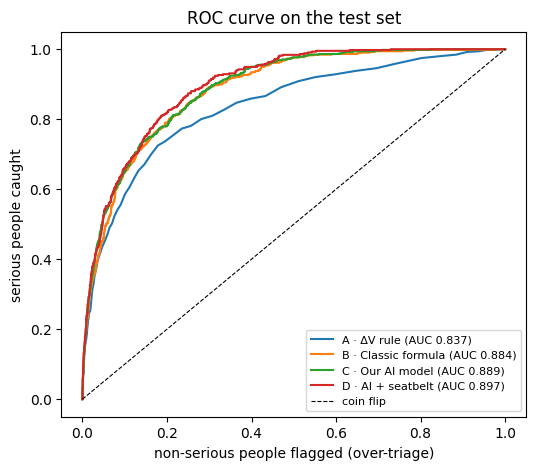

In [6]:
models = {
    "A · ΔV rule":        (model_a, ["dv_kmh"]),
    "B · Classic formula": (model_b, X_COLS),
    "C · Our AI model":    (model_c, X_COLS),
    "D · AI + seatbelt":   (model_d, X_COLS_BELT),
}

def over_triage_at(y, p, catch):
    """Share of non-serious people flagged when the threshold catches `catch` of the serious ones."""
    threshold = np.quantile(p[y == 1], 1 - catch)
    return (p[y == 0] >= threshold).mean()

rows, test_probs = [], {}
for name, (model, cols) in models.items():
    p = model.predict_proba(test[cols])[:, 1]
    test_probs[name] = p
    rows.append({
        "model": name,
        "AUC": roc_auc_score(y_test, p),
        "AUC (US-weighted)": roc_auc_score(y_test, p, sample_weight=test["casewgt"]),
        "over-triage @ catch 90%": over_triage_at(y_test.values, p, 0.90),
        "over-triage @ catch 95%": over_triage_at(y_test.values, p, 0.95),
    })
results = pd.DataFrame(rows).set_index("model")

belt_known = test["belt_used"].notna().values
yb = y_test.values[belt_known]
pc, pd_ = test_probs["C · Our AI model"][belt_known], test_probs["D · AI + seatbelt"][belt_known]
auc_c, auc_d = roc_auc_score(yb, pc), roc_auc_score(yb, pd_)
ot_c, ot_d = over_triage_at(yb, pc, 0.90), over_triage_at(yb, pd_, 0.90)
results.loc["D · AI + seatbelt"] = [auc_d, roc_auc_score(yb, pd_, sample_weight=test["casewgt"].values[belt_known]),
                                    ot_d, over_triage_at(yb, pd_, 0.95)]
print(results.round(3).to_string())
print(f"\n(D scored on the {belt_known.sum():,} test people whose belt use is known)")
print(f"On those people, without the car's belt sensor we lose {auc_d - auc_c:.3f} AUC "
      f"and flag {ot_c - ot_d:+.1%} more non-serious people at 90% catch.")

fig, ax = plt.subplots(figsize=(6, 5))
for name, p in test_probs.items():
    m = belt_known if name.startswith("D") else np.ones(len(p), bool)
    fpr, tpr, _ = roc_curve(y_test.values[m], p[m])
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test.values[m], p[m]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="coin flip")
ax.set_xlabel("non-serious people flagged (over-triage)")
ax.set_ylabel("serious people caught")
ax.set_title("ROC curve on the test set")
ax.legend(fontsize=8)
plt.show()

## 7 · What the AI model learned

**Importance**: how much each input helped the trees split serious from non-serious cases.

**Risk curves**: we invent people and crashes and ask the model. This shows the model behaves sensibly (risk grows with ΔV, is higher for older people and for side impacts).

Share of the model's decisions explained by each input:
dv_kmh          65.8 %
age             13.4 %
multi_impact     6.6 %
pdof_cos         5.0 %
pdof_sin         4.6 %
rollover         2.8 %
body_utility     0.7 %
male             0.6 %
body_pickup      0.3 %
body_van         0.1 %


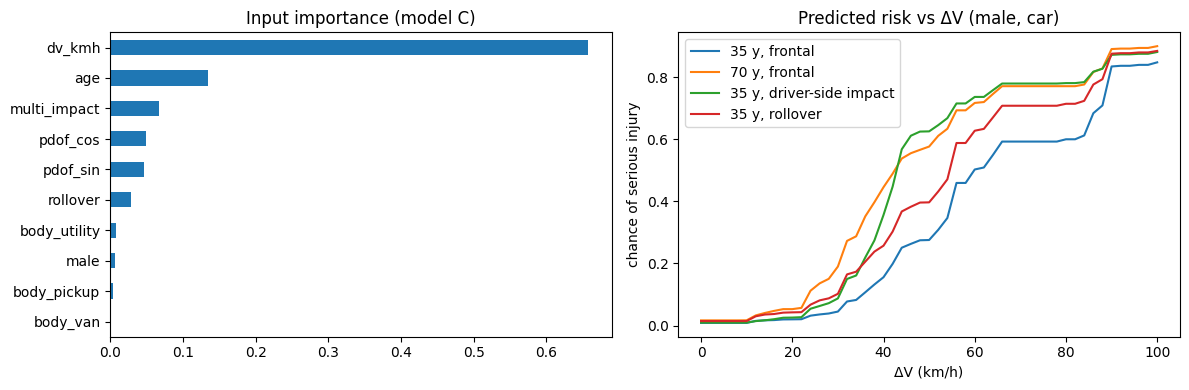

In [7]:
imp = pd.Series(model_c.booster_.feature_importance("gain"), index=X_COLS)
imp = (imp / imp.sum()).sort_values()
print("Share of the model's decisions explained by each input:")
print((imp[::-1] * 100).round(1).astype(str).add(" %").to_string())

def scenario(dv, angle=0, age=35, male=1, rollover=0, multi=0):
    return pd.DataFrame({
        "dv_kmh": dv, "pdof_sin": np.sin(np.radians(angle)), "pdof_cos": np.cos(np.radians(angle)),
        "rollover": rollover, "multi_impact": multi, "age": age, "male": male,
        "body_utility": 0.0, "body_van": 0.0, "body_pickup": 0.0,
    })[X_COLS]

dv = np.arange(0, 101, 2, dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
imp.plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Input importance (model C)")
for label, kw in [("35 y, frontal", {}), ("70 y, frontal", {"age": 70}),
                  ("35 y, driver-side impact", {"angle": 270}), ("35 y, rollover", {"rollover": 1})]:
    axes[1].plot(dv, model_c.predict_proba(scenario(dv, **kw))[:, 1], label=label)
axes[1].set_xlabel("ΔV (km/h)")
axes[1].set_ylabel("chance of serious injury")
axes[1].set_title("Predicted risk vs ΔV (male, car)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8 · From a probability to 4 levels

Dispatch needs a level, not a number. We pick thresholds on the **validation** set (not the test set, to keep the test honest):

| Level | Rule | Meaning |
|---|---|---|
| **extreme** | chance ≥ 50 % | more likely injured seriously than not |
| **high** | above the line that catches **90 %** of serious cases | the paper's standard operating point |
| **medium** | above the line that catches **95 %** of serious cases | safety margin |
| **low** | below that | very unlikely to be serious |

Profile flags (pregnancy, heart disease, blood thinners) raise the level by one **as a rule outside the model**, since the databases don't record them.

Then we check on the test set how predicted levels match the real injuries.

In [8]:
p_valid = model_c.predict_proba(valid[X_COLS])[:, 1]
serious_valid = p_valid[y_valid.values == 1]
THRESHOLDS = {
    "medium":  float(np.quantile(serious_valid, 0.05)),   # catches 95 % of serious cases
    "high":    float(np.quantile(serious_valid, 0.10)),   # catches 90 %
    "extreme": 0.50,
}
assert THRESHOLDS["medium"] <= THRESHOLDS["high"] <= THRESHOLDS["extreme"]
LEVELS = ["low", "medium", "high", "extreme"]

def to_level(p):
    return np.select([p >= THRESHOLDS["extreme"], p >= THRESHOLDS["high"], p >= THRESHOLDS["medium"]],
                     ["extreme", "high", "medium"], default="low")

print("Thresholds on the chance of serious injury:")
for level, t in THRESHOLDS.items():
    print(f"  {level:<8} from {t:.1%}")

pred_level = pd.Categorical(to_level(test_probs["C · Our AI model"]), LEVELS)
true_level = pd.Categorical(test["severity4"], LEVELS)
table = pd.crosstab(pd.Series(true_level, name="real injury"), pd.Series(pred_level, name="predicted level"),
                    normalize="index") * 100
print("\nTest set: for each real injury level, % of people put in each predicted level")
print(table.round(1).to_string())

serious = test["severity4"].isin(["high", "extreme"]).values
flagged = np.isin(pred_level, ["high", "extreme"])
print(f"\nSeriously injured people predicted high or extreme: {flagged[serious].mean():.1%}")
print(f"Seriously injured people predicted low (the dangerous miss): {(pred_level[serious] == 'low').mean():.1%}")
print(f"Not-serious people predicted high or extreme (extra ambulances): {flagged[~serious].mean():.1%}")

Thresholds on the chance of serious injury:
  medium   from 2.2%
  high     from 3.6%
  extreme  from 50.0%

Test set: for each real injury level, % of people put in each predicted level
predicted level   low  medium  high  extreme
real injury                                 
low              47.9    16.0  35.4      0.8
medium           18.7    11.1  65.6      4.5
high              2.7     4.0  77.7     15.7
extreme           0.0     3.2  56.9     39.8

Seriously injured people predicted high or extreme: 94.8%
Seriously injured people predicted low (the dangerous miss): 1.6%
Not-serious people predicted high or extreme (extra ambulances): 39.6%


## 9 · Save the model

We save model C plus everything needed to use it: the input list, the thresholds and the test scores. The backend's AI API will load these two files.

In [9]:
out = Path("models")
out.mkdir(exist_ok=True)
joblib.dump(model_c, out / "m3_lgbm.joblib")
config = {
    "features": X_COLS,
    "feature_notes": FEATURES,
    "thresholds": THRESHOLDS,
    "levels": LEVELS,
    "target": "P(MAIS 3+), trained unweighted on NASS-CDS 2010-15 + CISS 2017-23",
    "test_scores": results.loc["C · Our AI model"].round(4).to_dict(),
    "trees": int(model_c.best_iteration_),
}
(out / "m3_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
print("Saved:")
for f in sorted(out.iterdir()):
    print(f"  {f}  ({f.stat().st_size / 1024:.0f} KB)")

Saved:
  models/m3_config.json  (1 KB)
  models/m3_lgbm.joblib  (315 KB)


## 10 · Try it on example crashes

This is what the backend will do when the blackbox reports a crash: build the inputs, ask the model, print the level.

In [10]:
def predict_crash(dv_kmh, direction_deg, age, male, rollover=0, multi_impact=0, vehicle="car"):
    x = pd.DataFrame([{
        "dv_kmh": dv_kmh,
        "pdof_sin": np.sin(np.radians(direction_deg)), "pdof_cos": np.cos(np.radians(direction_deg)),
        "rollover": rollover, "multi_impact": multi_impact, "age": age, "male": male,
        "body_utility": float(vehicle == "utility"), "body_van": float(vehicle == "van"),
        "body_pickup": float(vehicle == "pickup"),
    }])[X_COLS]
    p = model_c.predict_proba(x)[0, 1]
    return p, str(to_level(np.array([p]))[0])

examples = [
    ("Parking bump, rear, 30 y man",            dict(dv_kmh=8,  direction_deg=180, age=30, male=1)),
    ("City crash, front, 25 y woman",           dict(dv_kmh=25, direction_deg=0,   age=25, male=0)),
    ("RN5 guardrail at 90 km/h, 45 y man",      dict(dv_kmh=55, direction_deg=10,  age=45, male=1, multi_impact=1)),
    ("Hit on the driver door, 68 y man",        dict(dv_kmh=35, direction_deg=270, age=68, male=1)),
    ("Rollover on highway, 40 y woman",         dict(dv_kmh=40, direction_deg=90,  age=40, male=0, rollover=1, multi_impact=1)),
]
print(f"{'crash':<40} {'chance serious':>15}   level")
for name, kw in examples:
    p, level = predict_crash(**kw)
    print(f"{name:<40} {p:>14.1%}   {level}")

crash                                     chance serious   level
Parking bump, rear, 30 y man                       0.3%   low
City crash, front, 25 y woman                      2.6%   medium
RN5 guardrail at 90 km/h, 45 y man                43.5%   high
Hit on the driver door, 68 y man                  40.5%   high
Rollover on highway, 40 y woman                   47.4%   high


## Notes for the pitch

- Trained on **~30,000 real investigated US crashes** (NASS-CDS 2010–15 + CISS 2017–23), with no car-sensor inputs (no belt, no airbag): **AUC 0.889** on crashes it never saw, about the same as published systems that *do* use them (0.835–0.873).
- Set to catch 95 % of seriously injured people, it sends **"low" to only 1.6 %** of them (the dangerous miss); the price is extra ambulances for ~40 % of non-serious cases.
- The car's belt sensor would add only **+0.014 AUC**: the blackbox alone is enough.
- **Data check we did:** a missing value in these databases is not random (missing BMI = uninjured in CISS but dead in NASS; missing direction = lighter crashes). We removed BMI and kept only crashes with a known direction, so the model can't learn "missing = answer". BMI turned out to add nothing real.
- Probabilities are on the *investigated crash* mix (serious crashes are over-represented), so read them as a **ranking**: the levels are what dispatch uses.
- ΔV in these databases comes from crash reconstruction; our blackbox measures it directly. When real blackbox data exists, we recalibrate on it.